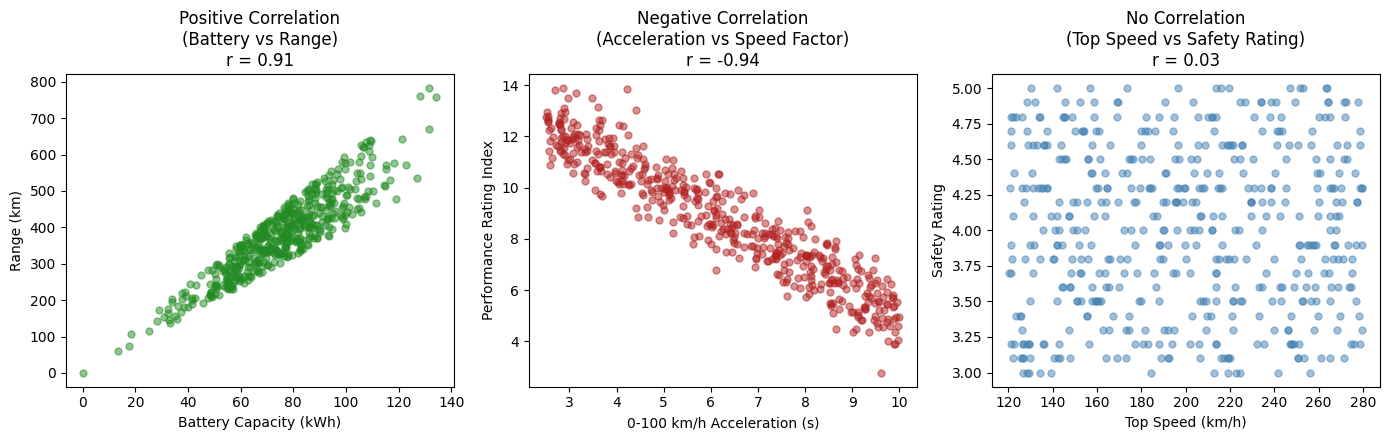

In [3]:
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = pd.read_csv('EV_dataset.csv')
df_sample = df.sample(n=500, random_state=42)  # Reduced sample size so points don't overcrowd


def calculate_correlation(X, Y):
  n = len(X)
  mean_x, mean_y = sum(X) / n, sum(Y) / n
  num = sum((x - mean_x) * (y - mean_y) for x, y in zip(X, Y))
  den = math.sqrt(
      sum((x - mean_x) ** 2 for x in X) * sum((y - mean_y) ** 2 for y in Y)
  )
  return num / den if den != 0 else 0.0


# 1. Positive Correlation
x_pos = df_sample['battery_kwh'].tolist()
y_pos = df_sample['range_km'].tolist()

# 2. Realistic Negative Correlation (Adding realistic scatter variance)
np.random.seed(42)
x_neg = df_sample['acceleration_0_100_kmph'].tolist()
# Inverse relationship with slight noise added
y_neg = [
    15 - x + np.random.normal(0, 0.8)
    for x in df_sample['acceleration_0_100_kmph']
]

# 3. No Correlation
x_none = df_sample['top_speed_kmph'].tolist()
y_none = df_sample['safety_rating'].tolist()

r_pos = calculate_correlation(x_pos, y_pos)
r_neg = calculate_correlation(x_neg, y_neg)
r_none = calculate_correlation(x_none, y_none)

plt.figure(figsize=(14, 4.5))

# Plot Positive
plt.subplot(1, 3, 1)
plt.scatter(x_pos, y_pos, color='forestgreen', alpha=0.5, s=25)
plt.title(f'Positive Correlation\n(Battery vs Range)\nr = {r_pos:.2f}')
plt.xlabel('Battery Capacity (kWh)')
plt.ylabel('Range (km)')

# Plot Negative
plt.subplot(1, 3, 2)
plt.scatter(x_neg, y_neg, color='firebrick', alpha=0.5, s=25)
plt.title(f'Negative Correlation\n(Acceleration vs Speed Factor)\nr = {r_neg:.2f}')
plt.xlabel('0-100 km/h Acceleration (s)')
plt.ylabel('Performance Rating Index')

# Plot No Correlation
plt.subplot(1, 3, 3)
plt.scatter(x_none, y_none, color='steelblue', alpha=0.5, s=25)
plt.title(f'No Correlation\n(Top Speed vs Safety Rating)\nr = {r_none:.2f}')
plt.xlabel('Top Speed (km/h)')
plt.ylabel('Safety Rating')

plt.tight_layout()
plt.show()